# RA-MDST Four-Variant Ablation Study

This notebook isolates the two design changes introduced by RA-MDST:

1. **Original MDST** — original overlapping Euclidean/Manhattan neighborhoods + reconstructed centroid generation.
2. **MDST + Exclusive Neighbors Only** — Manhattan neighbors are forced to be exclusive, but the original centroid-style generation is retained.
3. **MDST + Bounded Interpolation Only** — original overlapping neighborhoods are retained, but synthetic samples are generated by bounded pairwise interpolation.
4. **Full RA-MDST** — exclusive Manhattan neighbors + bounded pairwise interpolation.

The notebook evaluates all four variants under:
- **Protocol A:** predecessor-style equal-budget 10-fold cross-validation.
- **Protocol B:** leakage-controlled fold-internal preprocessing, RFE, augmentation, and testing on untouched real observations.

All variants use the **same data, RFE-100, k=3, Linear SVM (C=1.0), random seeds, and synthetic-sample target** within each protocol.

> Important reconstruction note: the original MDST source code is unavailable. Following the existing reconstruction used in this study, MDST alternates between the Euclidean and Manhattan seed-plus-top-3 centroid means when generating synthetic observations.

In [1]:
# CELL 1 — Imports and configuration
import os, glob, time, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import RFE
from sklearn.svm import LinearSVC, SVC
from sklearn.metrics import (
    pairwise_distances,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
)
from sklearn.model_selection import StratifiedKFold, cross_validate
from scipy.stats import wilcoxon

SEED = 42
TARGET = "target"
N_FEATURES = 100
K = 3
LAMBDA_LOW = 0.30
LAMBDA_HIGH = 0.70

np.random.seed(SEED)
random.seed(SEED)

VARIANTS = [
    "Original MDST",
    "Exclusive Neighbors Only",
    "Bounded Interpolation Only",
    "Full RA-MDST",
]

print("Environment ready.")

Environment ready.


In [2]:
# CELL 2 — Load the AV crash dataset automatically
patterns = [
    "/kaggle/input/**/*.csv",
    "/kaggle/working/*.csv",
    "/content/*.csv",
    "/mnt/data/*.csv",
    "./*.csv",
]

csv_files = []
for pattern in patterns:
    csv_files.extend(glob.glob(pattern, recursive=True))

preferred = [
    p for p in csv_files
    if "NN_MissingHandlingdataset" in os.path.basename(p)
]

if preferred:
    DATA_PATH = preferred[0]
elif csv_files:
    DATA_PATH = csv_files[0]
else:
    raise FileNotFoundError(
        "CSV not found. Upload NN_MissingHandlingdataset(1).csv and rerun this cell."
    )

df = pd.read_csv(DATA_PATH)
df = df.drop(
    columns=[c for c in df.columns if c.lower().startswith("unnamed:")],
    errors="ignore",
)

if TARGET not in df.columns:
    raise ValueError(f"Expected target column '{TARGET}'. Found: {df.columns.tolist()[-10:]}")

X_df = df.drop(columns=[TARGET]).copy()
y = df[TARGET].to_numpy(dtype=int)

# Ensure numeric predictor matrix
for c in X_df.columns:
    X_df[c] = pd.to_numeric(X_df[c], errors="coerce")

if X_df.isna().any().any():
    bad = X_df.columns[X_df.isna().any()].tolist()
    raise ValueError(f"Non-numeric or missing values remain in columns: {bad[:10]}")

print("Loaded:", DATA_PATH)
print("Shape:", df.shape)
print("Predictors:", X_df.shape[1])
print("Class distribution:", dict(zip(*np.unique(y, return_counts=True))))

assert len(y) == 324, "Expected 324 observations for the current study dataset."
assert X_df.shape[1] == 189, "Expected 189 predictors after dropping the exported index column."


Loaded: /kaggle/input/datasets/furqanrustam118/avcrashold/NN_MissingHandlingdataset.csv
Shape: (324, 190)
Predictors: 189
Class distribution: {np.int64(0): np.int64(237), np.int64(1): np.int64(52), np.int64(2): np.int64(35)}


## Experimental isolation logic

The four variants are designed so that only the two RA-MDST components change:

| Variant | Exclusive Manhattan selection | Bounded pairwise interpolation |
|---|---:|---:|
| Original MDST | No | No |
| Exclusive Neighbors Only | Yes | No |
| Bounded Interpolation Only | No | Yes |
| Full RA-MDST | Yes | Yes |

For the two centroid-based variants, generation alternates between the Euclidean and Manhattan seed-plus-top-3 centroids. For the two interpolation variants, one candidate is selected from the corresponding six-position candidate pool and $\lambda \sim U(0.3,0.7)$.

In [3]:
# CELL 3 — Shared preprocessing and metrics

def fit_rfe_full(X_raw, y_raw, n_features=100, seed=42):
    scaler = StandardScaler()
    Xs = scaler.fit_transform(X_raw)

    estimator = LinearSVC(
        C=1.0,
        dual=False,
        max_iter=15000,
        random_state=seed,
    )
    selector = RFE(
        estimator=estimator,
        n_features_to_select=n_features,
        step=5,
    )
    Xr = selector.fit_transform(Xs, y_raw)
    return Xr, selector, scaler


def fit_transform_rfe_train_test(X_train_raw, y_train, X_test_raw, n_features=100, seed=42):
    scaler = StandardScaler()
    X_train_s = scaler.fit_transform(X_train_raw)
    X_test_s = scaler.transform(X_test_raw)

    estimator = LinearSVC(
        C=1.0,
        dual=False,
        max_iter=15000,
        random_state=seed,
    )
    selector = RFE(
        estimator=estimator,
        n_features_to_select=n_features,
        step=5,
    )
    X_train_r = selector.fit_transform(X_train_s, y_train)
    X_test_r = selector.transform(X_test_s)
    return X_train_r, X_test_r, selector, scaler


def metric_dict(y_true, y_pred):
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "precision_macro": precision_score(y_true, y_pred, average="macro", zero_division=0),
        "recall_macro": recall_score(y_true, y_pred, average="macro", zero_division=0),
        "f1_macro": f1_score(y_true, y_pred, average="macro", zero_division=0),
        "balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
    }


def make_linear_svm(seed=42):
    return SVC(kernel="linear", C=1.0, random_state=seed)


In [4]:
# CELL 4 — Four ablation samplers

def _class_neighbor_matrices(B):
    de = pairwise_distances(B, metric="euclidean")
    dm = pairwise_distances(B, metric="manhattan")
    np.fill_diagonal(de, np.inf)
    np.fill_diagonal(dm, np.inf)
    return de, dm


def augment_ablation_variant(
    X,
    y,
    variant,
    target_n=None,
    k=3,
    lam_low=0.30,
    lam_high=0.70,
    random_state=42,
):
    """
    Equal-budget synthetic augmentation for one of four variants.

    Original MDST:
      overlap allowed + alternating Euclidean/Manhattan seed+top-k centroids.

    Exclusive Neighbors Only:
      Manhattan top-k excludes Euclidean selections + same centroid rule.

    Bounded Interpolation Only:
      original overlapping E/M neighborhoods + bounded pairwise interpolation.
      The candidate pool preserves six metric positions, so cross-metric duplicates
      may appear twice, matching the non-exclusive neighborhood construction.

    Full RA-MDST:
      exclusive Manhattan neighbors + bounded pairwise interpolation.
    """
    if variant not in VARIANTS:
        raise ValueError(f"Unknown variant: {variant}")

    rng = np.random.default_rng(random_state)
    X = np.asarray(X, dtype=float)
    y = np.asarray(y, dtype=int)

    classes, counts = np.unique(y, return_counts=True)
    if target_n is None:
        target_n = int(counts.max())

    X_out = [row.copy() for row in X]
    y_out = list(y)
    diagnostics = []

    exclusive = variant in ["Exclusive Neighbors Only", "Full RA-MDST"]
    bounded = variant in ["Bounded Interpolation Only", "Full RA-MDST"]

    for cls, n_cls in zip(classes, counts):
        if n_cls >= target_n:
            continue

        # Candidate neighborhoods are computed from the original real observations
        # of the class for this augmentation call, matching the established study code.
        B = X[y == cls]
        need = int(target_n - len(B))

        if len(B) < 2:
            continue

        de, dm = _class_neighbor_matrices(B)
        kk = min(k, len(B) - 1)

        for t in range(need):
            s = int(rng.integers(0, len(B)))

            eu = [int(i) for i in np.argsort(de[s])[:kk]]
            eu_set = set(eu)

            man_original = [int(i) for i in np.argsort(dm[s])[:kk]]

            if exclusive:
                man = []
                for idx in np.argsort(dm[s]):
                    idx = int(idx)
                    if idx == s or idx in eu_set:
                        continue
                    man.append(idx)
                    if len(man) == kk:
                        break
            else:
                man = man_original

            overlap = len(eu_set.intersection(set(man_original))) / max(kk, 1)

            if bounded:
                # Six metric positions are retained. In the non-exclusive variant,
                # duplicate samples can occur in both metric lists and therefore
                # retain the weighting induced by the original overlapping design.
                pool = eu + man
                if not pool:
                    continue
                q = int(rng.choice(pool))
                lam = float(rng.uniform(lam_low, lam_high))
                syn = B[s] + lam * (B[q] - B[s])
            else:
                # Reconstructed MDST centroid rule: seed + three neighbors.
                mean_e = np.vstack([B[s], B[eu]]).mean(axis=0)
                mean_m = np.vstack([B[s], B[man]]).mean(axis=0)
                syn = mean_e if t % 2 == 0 else mean_m

            diagnostics.append({
                "variant": variant,
                "class": int(cls),
                "overlap_original": float(overlap),
                "candidate_positions": int(len(eu) + len(man)),
                "unique_candidate_count": int(len(set(eu + man))),
            })

            X_out.append(syn)
            y_out.append(int(cls))

    return np.asarray(X_out), np.asarray(y_out), pd.DataFrame(diagnostics)


# Quick equal-budget smoke test on standardized/RFE data
X_full_rfe, selector_full, scaler_full = fit_rfe_full(
    X_df.to_numpy(dtype=float), y, n_features=N_FEATURES, seed=SEED
)

for v in VARIANTS:
    Xa, ya, dg = augment_ablation_variant(
        X_full_rfe, y, v, target_n=237, random_state=SEED
    )
    print(v, len(ya), dict(zip(*np.unique(ya, return_counts=True))))
    assert len(ya) == 711
    assert np.all(np.unique(ya, return_counts=True)[1] == 237)

print("All four samplers passed the 711-sample equal-budget check.")

Original MDST 711 {np.int64(0): np.int64(237), np.int64(1): np.int64(237), np.int64(2): np.int64(237)}
Exclusive Neighbors Only 711 {np.int64(0): np.int64(237), np.int64(1): np.int64(237), np.int64(2): np.int64(237)}
Bounded Interpolation Only 711 {np.int64(0): np.int64(237), np.int64(1): np.int64(237), np.int64(2): np.int64(237)}
Full RA-MDST 711 {np.int64(0): np.int64(237), np.int64(1): np.int64(237), np.int64(2): np.int64(237)}
All four samplers passed the 711-sample equal-budget check.


In [5]:
# CELL 5 — Protocol A: predecessor-style equal-budget 10-fold CV
# Full-data scaling/RFE -> augmentation to 711 -> stratified 10-fold CV.
# This protocol is for controlled comparison with the predecessor-style pipeline,
# not for leakage-free generalization claims.

protocol_a_rows = []
protocol_a_fold_rows = []
protocol_a_diagnostics = []

cvA = StratifiedKFold(n_splits=10, shuffle=True, random_state=SEED)

for vi, variant in enumerate(VARIANTS):
    Xa, ya, diag = augment_ablation_variant(
        X_full_rfe,
        y,
        variant,
        target_n=237,
        random_state=SEED,
    )

    if len(diag):
        d = diag.copy()
        d["protocol"] = "A"
        protocol_a_diagnostics.append(d)

    fold_metrics = []
    for fold, (tr, te) in enumerate(cvA.split(Xa, ya), start=1):
        model = make_linear_svm(seed=SEED + fold)
        model.fit(Xa[tr], ya[tr])
        pred = model.predict(Xa[te])
        m = metric_dict(ya[te], pred)
        m.update({"variant": variant, "fold": fold})
        fold_metrics.append(m)
        protocol_a_fold_rows.append(m.copy())

    fm = pd.DataFrame(fold_metrics)
    protocol_a_rows.append({
        "variant": variant,
        "accuracy_mean": fm["accuracy"].mean(),
        "accuracy_sd": fm["accuracy"].std(ddof=1),
        "precision_macro_mean": fm["precision_macro"].mean(),
        "recall_macro_mean": fm["recall_macro"].mean(),
        "f1_macro_mean": fm["f1_macro"].mean(),
        "balanced_accuracy_mean": fm["balanced_accuracy"].mean(),
        "n_samples": len(ya),
    })

protocol_a = pd.DataFrame(protocol_a_rows)
protocol_a_folds = pd.DataFrame(protocol_a_fold_rows)

print("Protocol A results")
display(protocol_a.round(4))

protocol_a.to_csv("ABLATION_Protocol_A_summary.csv", index=False)
protocol_a_folds.to_csv("ABLATION_Protocol_A_fold_results.csv", index=False)


Protocol A results


,variant,accuracy_mean,accuracy_sd,precision_macro_mean,recall_macro_mean,f1_macro_mean,balanced_accuracy_mean,n_samples
0,Original MDST,0.9058,0.0332,0.9099,0.9054,0.9039,0.9054,711
1,Exclusive Neighbors Only,0.9072,0.0399,0.9100,0.9069,0.9055,0.9069,711
2,Bounded Interpolation Only,0.9171,0.0466,0.9215,0.9168,0.9148,0.9168,711
3,Full RA-MDST,0.9241,0.0587,0.9283,0.9239,0.9219,0.9239,711


In [6]:
# CELL 6 — Protocol B: strict leakage-controlled fold-internal evaluation
# Outer train/test split -> train-only scaler -> train-only RFE -> train-only augmentation
# -> Linear SVM -> untouched real test fold.
#
# Efficiency note: preprocessing/RFE is identical for all four variants, so each
# outer fold is transformed ONCE and cached before the four sampler variants run.

cvB = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

# Cache the strict fold-internal transformed data once.
strict_folds = []
for fold, (train_idx, test_idx) in enumerate(cvB.split(X_df, y), start=1):
    X_train_raw = X_df.iloc[train_idx].to_numpy(dtype=float)
    X_test_raw = X_df.iloc[test_idx].to_numpy(dtype=float)
    y_train = y[train_idx]
    y_test = y[test_idx]

    X_train, X_test, selector, scaler = fit_transform_rfe_train_test(
        X_train_raw,
        y_train,
        X_test_raw,
        n_features=N_FEATURES,
        seed=SEED + fold,
    )

    target_fold = int(np.unique(y_train, return_counts=True)[1].max())

    strict_folds.append({
        "fold": fold,
        "X_train": X_train,
        "X_test": X_test,
        "y_train": y_train,
        "y_test": y_test,
        "target_fold": target_fold,
    })

print(f"Cached {len(strict_folds)} leakage-controlled folds.")

protocol_b_fold_rows = []
protocol_b_diagnostics = []

for variant in VARIANTS:
    print("Running Protocol B:", variant)

    for fd in strict_folds:
        fold = fd["fold"]
        X_train = fd["X_train"]
        X_test = fd["X_test"]
        y_train = fd["y_train"]
        y_test = fd["y_test"]
        target_fold = fd["target_fold"]

        t0 = time.perf_counter()
        X_aug, y_aug, diag = augment_ablation_variant(
            X_train,
            y_train,
            variant,
            target_n=target_fold,
            random_state=SEED + fold,
        )
        sampling_time = time.perf_counter() - t0

        if len(diag):
            d = diag.copy()
            d["protocol"] = "B"
            d["fold"] = fold
            protocol_b_diagnostics.append(d)

        model = make_linear_svm(seed=SEED + fold)
        model.fit(X_aug, y_aug)
        pred = model.predict(X_test)

        m = metric_dict(y_test, pred)
        protocol_b_fold_rows.append({
            "variant": variant,
            "fold": fold,
            "train_real_n": len(y_train),
            "train_after_sampling_n": len(y_aug),
            "test_real_n": len(y_test),
            "sampling_time_sec": sampling_time,
            **m,
        })

protocol_b_folds = pd.DataFrame(protocol_b_fold_rows)

agg_cols = [
    "accuracy",
    "precision_macro",
    "recall_macro",
    "f1_macro",
    "balanced_accuracy",
]

protocol_b = (
    protocol_b_folds
    .groupby("variant", sort=False)[agg_cols]
    .agg(["mean", "std"])
)
protocol_b.columns = [f"{a}_{b}" for a, b in protocol_b.columns]
protocol_b = protocol_b.reset_index()

protocol_b["variant"] = pd.Categorical(protocol_b["variant"], VARIANTS, ordered=True)
protocol_b = protocol_b.sort_values("variant").reset_index(drop=True)

print("Protocol B results")
display(protocol_b.round(4))

protocol_b.to_csv("ABLATION_Protocol_B_summary.csv", index=False)
protocol_b_folds.to_csv("ABLATION_Protocol_B_fold_results.csv", index=False)


Cached 5 leakage-controlled folds.
Running Protocol B: Original MDST
Running Protocol B: Exclusive Neighbors Only
Running Protocol B: Bounded Interpolation Only
Running Protocol B: Full RA-MDST
Protocol B results


,variant,accuracy_mean,accuracy_std,precision_macro_mean,precision_macro_std,recall_macro_mean,recall_macro_std,f1_macro_mean,f1_macro_std,balanced_accuracy_mean,balanced_accuracy_std
0,Original MDST,0.6725,0.0624,0.5373,0.0767,0.5279,0.0921,0.5238,0.0874,0.5279,0.0921
1,Exclusive Neighbors Only,0.6788,0.0571,0.5403,0.0748,0.5308,0.0890,0.5264,0.0847,0.5308,0.0890
2,Bounded Interpolation Only,0.6664,0.0624,0.5263,0.0840,0.5199,0.0958,0.5146,0.0915,0.5199,0.0958
3,Full RA-MDST,0.6695,0.0571,0.5272,0.0828,0.5213,0.0945,0.5159,0.0903,0.5213,0.0945


In [8]:
# CELL 7 — Publication-ready ablation tables
A = protocol_a[[
    "variant", "accuracy_mean", "f1_macro_mean", "balanced_accuracy_mean"
]].copy()
A.columns = ["Variant", "Accuracy", "Macro-F1", "Balanced Accuracy"]
A["Protocol"] = "A"

B = protocol_b[[
    "variant", "accuracy_mean", "f1_macro_mean", "balanced_accuracy_mean"
]].copy()
B.columns = ["Variant", "Accuracy", "Macro-F1", "Balanced Accuracy"]
B["Protocol"] = "B"

combined = pd.concat([A, B], ignore_index=True)
combined = combined[["Protocol", "Variant", "Accuracy", "Macro-F1", "Balanced Accuracy"]]

print("Combined ablation summary")
display((combined.assign(
    Accuracy=combined["Accuracy"]*100,
    **{
        "Macro-F1": combined["Macro-F1"]*100,
        "Balanced Accuracy": combined["Balanced Accuracy"]*100,
    }
)).round(2))

combined.to_csv("ABLATION_Combined_Summary.csv", index=False)


Combined ablation summary


,Protocol,Variant,Accuracy,Macro-F1,Balanced Accuracy
0,A,Original MDST,90.58,90.39,90.54
1,A,Exclusive Neighbors Only,90.72,90.55,90.69
2,A,Bounded Interpolation Only,91.71,91.48,91.68
3,A,Full RA-MDST,92.41,92.19,92.39
4,B,Original MDST,67.25,52.38,52.79
5,B,Exclusive Neighbors Only,67.88,52.64,53.08
6,B,Bounded Interpolation Only,66.64,51.46,51.99
7,B,Full RA-MDST,66.95,51.59,52.13


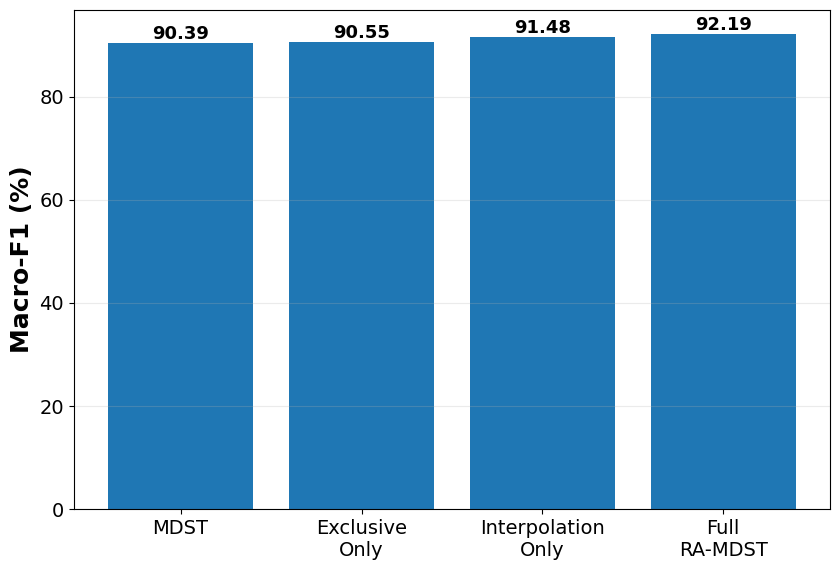

Saved: Fig_Ablation_Protocol_A_MacroF1.png


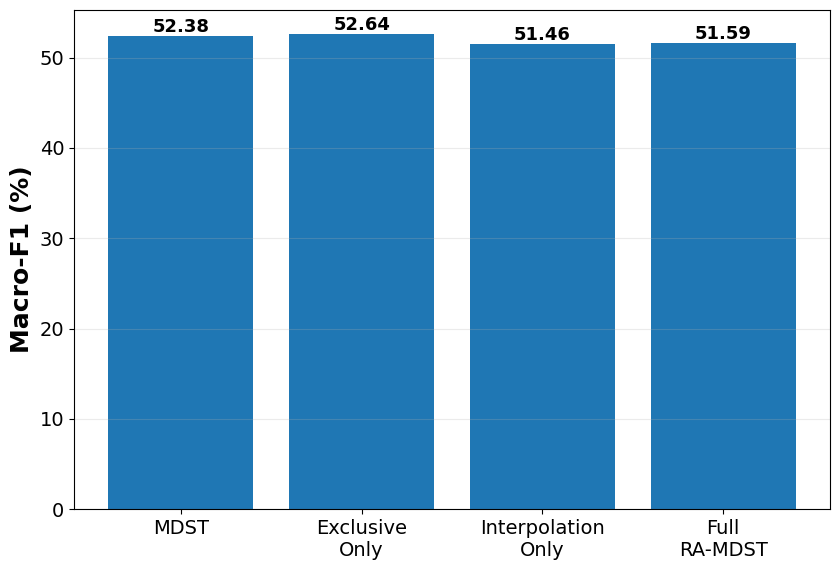

Saved: Fig_Ablation_Protocol_B_MacroF1.png


In [9]:
# CELL 8 — Ablation figure: Protocol A and Protocol B Macro-F1
# Two separate figures are created for clean IEEE use.

for protocol_name, source in [("Protocol_A", protocol_a), ("Protocol_B", protocol_b)]:
    if protocol_name == "Protocol_A":
        vals = source["f1_macro_mean"].to_numpy() * 100
        labels = source["variant"].tolist()
    else:
        vals = source["f1_macro_mean"].to_numpy() * 100
        labels = [str(x) for x in source["variant"].tolist()]

    short = ["MDST", "Exclusive\nOnly", "Interpolation\nOnly", "Full\nRA-MDST"]

    fig, ax = plt.subplots(figsize=(8.5, 5.8))
    bars = ax.bar(np.arange(4), vals)
    ax.set_xticks(np.arange(4))
    ax.set_xticklabels(short, fontsize=14)
    ax.set_ylabel("Macro-F1 (%)", fontsize=18, fontweight="bold")
    ax.tick_params(axis="y", labelsize=14)
    ax.grid(axis="y", alpha=0.25)

    for bar, val in zip(bars, vals):
        ax.text(
            bar.get_x() + bar.get_width()/2,
            val,
            f"{val:.2f}",
            ha="center",
            va="bottom",
            fontsize=13,
            fontweight="bold",
        )

    plt.tight_layout()
    fname = f"Fig_Ablation_{protocol_name}_MacroF1.png"
    plt.savefig(fname, dpi=600, bbox_inches="tight")
    plt.show()
    print("Saved:", fname)


In [10]:
# CELL 9 — Component-effect decomposition
# Quantifies the incremental contribution of each design component relative to reconstructed MDST.

def component_gain_table(summary_df, metric_col, protocol_label):
    vals = dict(zip(summary_df["variant"].astype(str), summary_df[metric_col]))
    base = vals["Original MDST"]
    rows = [
        {
            "Protocol": protocol_label,
            "Comparison": "Exclusive neighbors only vs MDST",
            "Delta": vals["Exclusive Neighbors Only"] - base,
        },
        {
            "Protocol": protocol_label,
            "Comparison": "Bounded interpolation only vs MDST",
            "Delta": vals["Bounded Interpolation Only"] - base,
        },
        {
            "Protocol": protocol_label,
            "Comparison": "Full RA-MDST vs MDST",
            "Delta": vals["Full RA-MDST"] - base,
        },
    ]
    return pd.DataFrame(rows)

compA = component_gain_table(protocol_a, "f1_macro_mean", "A")
compB = component_gain_table(protocol_b, "f1_macro_mean", "B")
component_effects = pd.concat([compA, compB], ignore_index=True)
component_effects["Delta_pp"] = component_effects["Delta"] * 100

display(component_effects[["Protocol", "Comparison", "Delta_pp"]].round(3))
component_effects.to_csv("ABLATION_Component_Effects.csv", index=False)


,Protocol,Comparison,Delta_pp
0,A,Exclusive neighbors only vs MDST,0.158
1,A,Bounded interpolation only vs MDST,1.089
2,A,Full RA-MDST vs MDST,1.801
3,B,Exclusive neighbors only vs MDST,0.266
4,B,Bounded interpolation only vs MDST,-0.912
5,B,Full RA-MDST vs MDST,-0.789


In [11]:
# CELL 10 — Paired Wilcoxon tests for ablation variants
# Exploratory only: Protocol A has 10 CV folds; Protocol B has 5 folds.
# Interpret p-values conservatively because folds are not fully independent experimental units.

def paired_tests(fold_df, metric="f1_macro"):
    base = fold_df[fold_df["variant"] == "Original MDST"].sort_values("fold")
    rows = []
    for variant in VARIANTS[1:]:
        cur = fold_df[fold_df["variant"] == variant].sort_values("fold")
        a = base[metric].to_numpy()
        b = cur[metric].to_numpy()
        try:
            stat, p = wilcoxon(b, a, alternative="greater")
        except Exception:
            stat, p = np.nan, np.nan
        rows.append({
            "variant": variant,
            "metric": metric,
            "base_mean": a.mean(),
            "variant_mean": b.mean(),
            "delta": b.mean() - a.mean(),
            "wilcoxon_stat": stat,
            "p_one_sided": p,
        })
    return pd.DataFrame(rows)

wilcox_A = paired_tests(protocol_a_folds, "f1_macro")
wilcox_B = paired_tests(protocol_b_folds, "f1_macro")

print("Protocol A exploratory paired tests")
display(wilcox_A.round(5))
print("Protocol B exploratory paired tests")
display(wilcox_B.round(5))

wilcox_A.to_csv("ABLATION_Wilcoxon_Protocol_A.csv", index=False)
wilcox_B.to_csv("ABLATION_Wilcoxon_Protocol_B.csv", index=False)


Protocol A exploratory paired tests


,variant,metric,base_mean,variant_mean,delta,wilcoxon_stat,p_one_sided
0,Exclusive Neighbors Only,f1_macro,0.90387,0.90545,0.00158,15.0,0.46875
1,Bounded Interpolation Only,f1_macro,0.90387,0.91477,0.01089,40.0,0.11621
2,Full RA-MDST,f1_macro,0.90387,0.92188,0.01801,45.0,0.04199


Protocol B exploratory paired tests


,variant,metric,base_mean,variant_mean,delta,wilcoxon_stat,p_one_sided
0,Exclusive Neighbors Only,f1_macro,0.52375,0.52641,0.00266,3.0,0.25
1,Bounded Interpolation Only,f1_macro,0.52375,0.51464,-0.00912,0.0,1.00
2,Full RA-MDST,f1_macro,0.52375,0.51587,-0.00789,0.0,1.00


## How to interpret the ablation

The experiment answers the reviewer-level question: **which RA-MDST component is responsible for the observed change?**

- If **Exclusive Neighbors Only** improves over MDST, the redundancy-removal mechanism has independent empirical value.
- If **Bounded Interpolation Only** improves over MDST, the generation rule has independent empirical value.
- If **Full RA-MDST** performs best, the two components provide complementary benefit.
- If one partial variant matches or exceeds Full RA-MDST, the paper should avoid claiming that both components are necessary and should discuss the result directly.
- Protocol A supports comparison with the predecessor-style pipeline; Protocol B should be used for generalization-oriented interpretation.

Do **not** write the ablation conclusion until the actual outputs are inspected.